In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import matplotlib

from sklearn.feature_selection import r_regression

In [2]:
os.chdir('/mnt/scratche/slow/halab/Jack/cellModel/figures/figure_2')

In [3]:
cell_types = ['HepG2', 'LNCaP', 'K562', 'HCT116', 'MCF7', 'U2OS', 'HEK293']

In [ ]:
# predictions of universal model
multi_preds = [pd.read_csv(f'all_cell_type_preds/test_fold_predictions_{c}.tsv', sep='\t')['predicted_Log2RPM'].values for c in cell_types]
# ground truth measurements of universal model
multi_meas = [pd.read_csv(f'all_cell_type_preds/test_fold_predictions_{c}.tsv', sep='\t')['measured_Log2PM'].values for c in cell_types]
# predictions of cell type specific models. `Random` here is a placeholder.
specific_preds = [pd.read_csv(f'cell_type_specific/{c.lower()}_out/test_fold_predictions_Random.tsv', sep='\t')['predicted_Log2RPM'].values for c in cell_types]

In [ ]:
# This uses the original data from https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE301246
test_fold = pd.read_csv('og-data/metadata_test.bed.gz', sep='\t')
test_fold['id'] = test_fold['chr']+ '_' + test_fold['start'].astype(str)+'_'+test_fold['end'].astype(str)

df = pd.read_csv(f'og-data/mh4_test.bed.gz', sep='\t')
df['id'] = df['chr']+ '_' + df['start'].astype(str)+'_'+df['end'].astype(str)

df_test = pd.merge(test_fold, df, how='inner', on=['chr', 'start', 'end','id', 'strand'])

specific_meas = []

for c in cell_types:
    specific_meas.append(df_test[f'Log2RPM_{c}'].values)

In [13]:
rs = [r_regression(multi_preds[i].reshape(-1, 1), multi_meas[i])[0] for i in range(len(cell_types))]
rs_cell = [r_regression(specific_preds[i].reshape(-1, 1), specific_meas[i])[0] for i in range(len(cell_types))]

meas_means = [np.mean(multi_meas[i]) for i in range(len(cell_types))]
meas_vars = [np.var(multi_meas[i]) for i in range(len(cell_types))]

pred_means = [np.mean(specific_preds[i]) for i in range(len(cell_types))]
pred_vars = [np.var(specific_preds[i]) for i in range(len(cell_types))]

In [16]:
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# Optional: we used the default (DejaVu Sans). Uncomment to switch to Arial/Helvetica.
# matplotlib.rcParams['font.family'] = 'sans-serif'
# matplotlib.rcParams['font.sans-serif'] = ['Arial', 'Helvetica']

REAL_COLOR = "#2c3e50"
PRED_COLOR = "#c0392b"
MEAN_COLOR = "#8e44ad"     # model mean-prediction line
FILL_ALPHA = 0.4           # density fills
LINE_WIDTH = 1.5           # density outlines

LABEL_SIZE = 10.5          # axis labels
TITLE_SIZE = 11            # panel title
LEGEND_SIZE = 8            # legend text

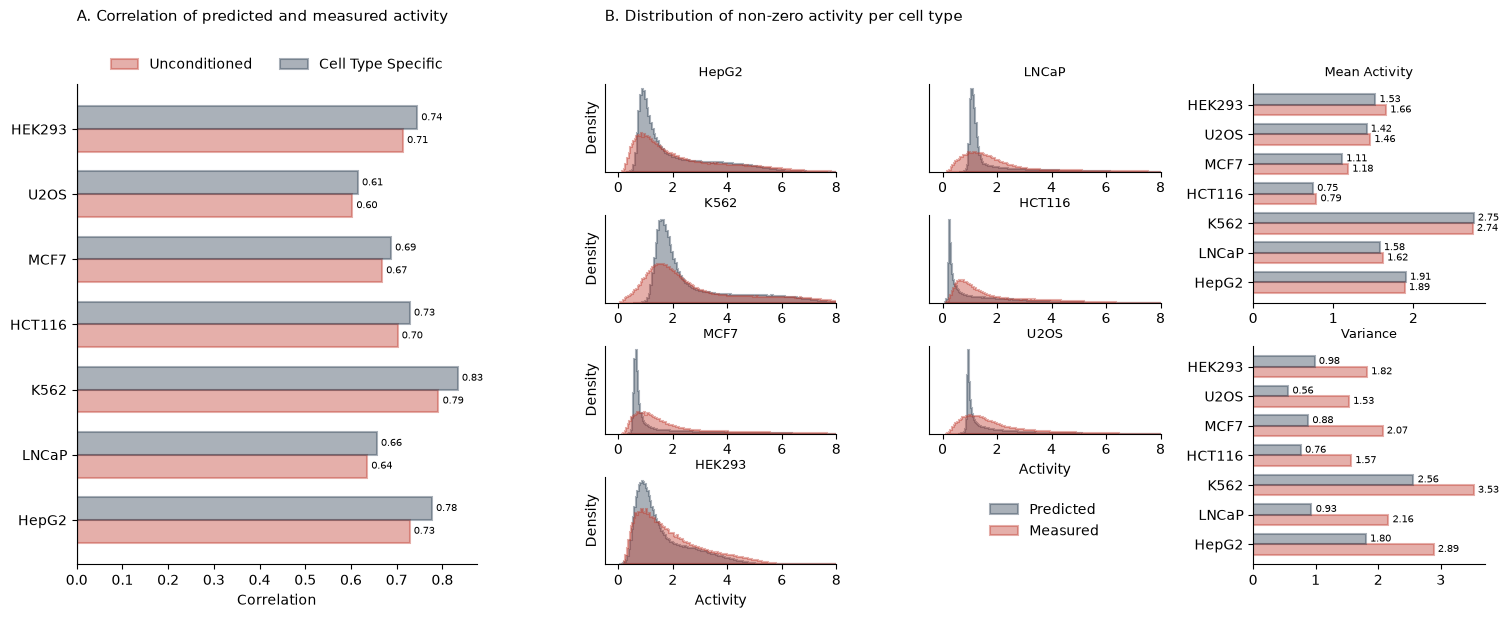

In [17]:
fig = plt.figure(figsize=(16, 6))

# outer grid: left block (A) vs right block (histograms + mean/var)
outer_gs = fig.add_gridspec(1, 2, width_ratios=[1, 2.2], wspace=0.2)

hist_gs = outer_gs[1].subgridspec(4, 3, wspace=0.4, hspace=0.5)

labels = cell_types
x = np.arange(len(labels))


# --- Panel A: bar chart ---
ax1 = fig.add_subplot(outer_gs[0])

barsa = ax1.barh(x - width/2, rs, width, alpha=FILL_ALPHA, color=PRED_COLOR, edgecolor=PRED_COLOR, linewidth=LINE_WIDTH, label=r'Unconditioned')
barsb = ax1.barh(x + width/2, rs_cell, width, alpha=FILL_ALPHA, color=REAL_COLOR, edgecolor=REAL_COLOR, linewidth=LINE_WIDTH,label=r'Cell Type Specific')
ax1.axvline(0, color='black', linewidth=0.8)
ax1.set_yticks(x)
ax1.set_yticklabels(labels)
ax1.set_xlabel(r'Correlation')
ax1.bar_label(barsa, fmt='%.2f', padding=3, fontsize=7)
ax1.bar_label(barsb, fmt='%.2f', padding=3, fontsize=7)
ax1.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncols=2, frameon=False)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.patch.set_facecolor('none')
ax1.set_title('')


# --- Panel C: histogram grid (8 subplots) ---
hist_axes = [fig.add_subplot(hist_gs[i // 2, i % 2], sharex=(None if i == 0 else fig.axes[-1]))
             for i in range(8)]

for i in range(len(hist_axes) - 1):
    hist_axes[i].hist(specific_preds[i][specific_meas[i] != 0], alpha=FILL_ALPHA, color=REAL_COLOR,
                       label=r'Predicted', bins=200, histtype='stepfilled', edgecolor=REAL_COLOR, linewidth=LINE_WIDTH,)
    hist_axes[i].hist(specific_meas[i][specific_meas[i] != 0], alpha=FILL_ALPHA, color=PRED_COLOR,
                       label=r'Measured', bins=200, histtype='stepfilled', edgecolor=PRED_COLOR, linewidth=LINE_WIDTH,)
    hist_axes[i].set_title(fr'{cell_types[i]}', fontsize=9)
    hist_axes[i].get_yaxis().set_visible(False)
    hist_axes[i].patch.set_facecolor('none')

hist_axes[-1].set_axis_off()

hist_axes[-2].set_xlabel(r'Activity')
hist_axes[-3].set_xlabel(r'Activity')

for a in hist_axes[:-1]:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

for i in range(len(hist_axes)):
    if i % 2 == 0:
        hist_axes[i].get_yaxis().set_visible(True)
        hist_axes[i].get_yaxis().set_ticks([])
        hist_axes[i].set_ylabel(r'Density')

custom_xlim = (-0.5, 8)
plt.setp(hist_axes[:-1], xlim=custom_xlim)

handles, labels_h = hist_axes[-2].get_legend_handles_labels()
hist_axes[-1].legend(handles, labels_h, loc='center', frameon=False)

# --- Mean / variance bars ---
ax_mean = fig.add_subplot(hist_gs[:2, 2:])
ax_var = fig.add_subplot(hist_gs[2:, 2:])

x = np.arange(len(labels))
width = 0.35

bars1a = ax_mean.barh(x - width/2, meas_means, width, color=PRED_COLOR, edgecolor=PRED_COLOR, linewidth=LINE_WIDTH, alpha=FILL_ALPHA, label='Measured')
bars1b = ax_mean.barh(x + width/2, pred_means, width, color=REAL_COLOR, edgecolor=REAL_COLOR, linewidth=LINE_WIDTH, alpha=FILL_ALPHA, label='Predicted')
ax_mean.set_yticks(x)
ax_mean.set_yticklabels(labels)
ax_mean.set_xlabel('')
ax_mean.bar_label(bars1a, fmt='%.2f', padding=3, fontsize=7)
ax_mean.bar_label(bars1b, fmt='%.2f', padding=3, fontsize=7)
ax_mean.set_title(r'Mean Activity', fontsize=9)

bars2a = ax_var.barh(x - width/2, meas_vars, width, color=PRED_COLOR, edgecolor=PRED_COLOR, linewidth=LINE_WIDTH, alpha=FILL_ALPHA, label='Measured')
bars2b = ax_var.barh(x + width/2, pred_vars, width, color=REAL_COLOR, edgecolor=REAL_COLOR, linewidth=LINE_WIDTH, alpha=FILL_ALPHA, label='Predicted')
ax_var.set_yticks(x)
ax_var.set_yticklabels(labels)
ax_var.set_xlabel('')
ax_var.bar_label(bars2a, fmt='%.2f', padding=3, fontsize=7)
ax_var.bar_label(bars2b, fmt='%.2f', padding=3, fontsize=7)
ax_var.set_title(r'Variance', fontsize=9)

for ax in (ax_mean, ax_var):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# trim outer whitespace
fig.subplots_adjust(top=0.88, bottom=0.08, left=0.09, right=0.97)

# --- Panel labels (after subplots_adjust so positions are final) ---
y_top = max(ax1.get_position().y1,
            max(a.get_position().y1 for a in hist_axes)) + 0.1

def label_panel(ax, text, y_fig, fontsize=11):
    pos = ax.get_position()
    ax.figure.text(pos.x0, y_fig, text, fontsize=fontsize,
                   fontweight='normal', va='bottom', ha='left')

label_panel(ax1, 'A. Correlation of predicted and measured activity', y_top)
label_panel(hist_axes[0], 'B. Distribution of non-zero activity per cell type', y_top)

plt.savefig('parm-figures.pdf', bbox_inches='tight')
plt.show()

## Supplementary Figure

In [19]:
cmap = 'viridis'

In [20]:
df = pd.DataFrame(multi_preds).T   # each column = one vector
df.columns = [cell for cell in cell_types]
corr_multi = df.corr() 

df = pd.DataFrame(specific_preds).T   # each column = one vector
df.columns = [cell for cell in cell_types]
corr_spec = df.corr()  

df = pd.DataFrame(multi_meas).T   # each column = one vector
df.columns = [cell for cell in cell_types]
corr_true = df.corr()

In [21]:
upper_mask = np.triu(np.ones_like(corr_true, dtype=bool), k=0)
combined = np.where(upper_mask, corr_true, corr_spec)

mat = combined

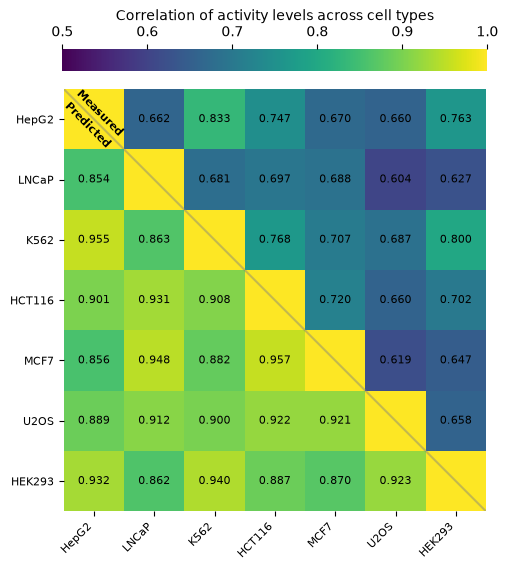

In [ ]:
from matplotlib.colors import to_rgba

def heatmap_panel(fig, ax, mat, labels, cmap, title=None,
                  vmin=0.5, vmax=1, delta=0.1):
    mat = np.asarray(mat)
    n = mat.shape[0]

    im = ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(np.arange(n))
    ax.set_yticks(np.arange(n))
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)

    for spine in ax.spines.values():
        spine.set_visible(False)

    # cell annotations (skip the diagonal of 1s)
    for i in range(n):
        for j in range(n):
            if mat[i, j] != 1:
                ax.text(j, i, f'{mat[i, j]:.3f}', ha='center', va='center',
                        fontsize=8, color='black')

    # diagonal split line
    ax.plot([-0.5, n - 0.5], [-0.5, n - 0.5], color=to_rgba('gray', 0.45), linewidth=1.5)

    # triangle labels along the diagonal
    ax.text(delta, -delta, 'Measured', ha='center', va='center', fontsize=8,
            fontweight='bold', rotation=-45, zorder=4)
    ax.text(-delta, delta, 'Predicted', ha='center', va='center', fontsize=8,
            fontweight='bold', rotation=-45, zorder=4)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04,
                        label='Correlation of activity levels across cell types', location='top')
    cbar.outline.set_edgecolor('none')

    ax.patch.set_facecolor('none')
    if title:
        ax.set_title(title, fontsize=11, loc='left', pad=45)  # pad clears the top colorbar
    return im


fig, ax = plt.subplots(figsize=(6, 6))
heatmap_panel(fig, ax, mat, cell_types, cmap,
              title='')
plt.savefig('parm-heatmap.pdf', bbox_inches='tight', transparent=True)
plt.show()